# Rhine Freight: forecasting the price 5 business days ahead

**Map of the notebook**

0. Setup and data
1. Baseline model
2. Features
3. Two training splits
4. Predicting Freight: 4.1 Lasso on every feature · 4.2 Lasso on Freight features · 4.3 Lasso delta · 4.4 Ridge · 4.5 Ridge delta · 4.6 XGBoost · 4.7 XGBoost delta · 4.8 Previous models on Freight features
5. Predicting Kaub level: 5.1 Lasso weather · 5.2 Making it rain
6. Predicting Freight with the help of Kaub: 6.1 Previous models with Kaub features · 6.2 Comparison without Kaub features
7. Predicting Freight using ARX
8. Quantile regression (risk band)
9. Conclusions
- Appendix: LSTM

**How to read the result tables**
- Each (sub)section ends with a results DataFrame. Numbers are the **mean across folds**; per-fold detail is only shown a few times.
- **Yellow rows = what is new in that step**, so you know where to look.
- Columns are grouped by training split (`expanding` / `rolling`). Metrics come from `metricas` / `metricas_pct`: MAE, RMSE, Erro máx (mean over folds of the per-fold max error), MAPE (%) and *MAE extremos* (MAE only on the "extreme days": actual 5-day-ahead price in the top 10%).

# 0. Setup and data

In [1]:
# Imports
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from IPython.display import display

from scipy.stats import randint, loguniform
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.linear_model import LassoCV, RidgeCV, LinearRegression
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Paths
DATA_DIR = Path("..") / "data"
CHARTS_DIR = Path("..") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Rhine Freight Data
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_freight['Date'] = pd.to_datetime(df_freight['Date'], dayfirst=True)
df_freight = df_freight.dropna(how="all")                     # drop empty rows

# Weather Data (dates are dd/mm/yyyy)
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")
df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True)
df_weather = df_weather.dropna(how="all")
df_weather.rename(columns={'date': 'Date'}, inplace=True)

df_complete = pd.merge(df_freight, df_weather, on='Date', how='left')
print("freight / weather / merged:", df_freight.shape, df_weather.shape, df_complete.shape)
df_complete.head()

freight / weather / merged: (1469, 8) (3652, 25) (1469, 32)


,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avg_uv_index,avgtemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,1.0,2.0,...,0.0,1.0,10.0,122.0,['Overcast'],245.0,WSW,7.0,1.0,14.0
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,1.0,4.0,...,0.0,1.0,0.0,248.0,['Fog'],283.0,WNW,6.0,3.0,12.0
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,1.0,1.0,...,0.0,1.0,10.0,113.0,['Clear'],105.0,ESE,5.0,-2.0,10.0
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,1.0,0.0,...,0.0,1.0,10.0,113.0,['Clear'],210.0,SSW,4.0,0.0,8.0
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,1.0,-1.0,...,0.0,1.0,5.0,143.0,['Mist'],273.0,W,5.0,-3.0,10.0


In [3]:
# Cleaning + target
df_complete.drop(columns=['avg_uv_index', 'uv_index', "weather_code", "wind_dir"], inplace=True)
df_complete["Kaub_level"] = df_complete["Kaub_level"].interpolate(method="linear", limit_area="inside")

df_complete.dropna(subset=['Freight'], inplace=True)
# Price 5 rows (= 5 business days) ahead; the last 5 rows have no future -> dropped
df_complete['Freight_5days'] = df_complete['Freight'].shift(-5)
df_complete = df_complete.dropna(subset=['Freight_5days']).reset_index(drop=True)

## Metric functions (`métricas`)

Every results table in this notebook is built from these two functions.

In [4]:
def metricas(y_true, y_pred):
    """MAE, RMSE and max absolute error. Accepts Series or arrays."""
    erro = np.abs(np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float))
    return {
        'MAE': erro.mean(),
        'RMSE': np.sqrt((erro ** 2).mean()),
        'Erro máx': erro.max(),
    }

def metricas_pct(y_true, y_pred):
    """metricas() + mean absolute error as a percentage of the actual price."""
    out = metricas(y_true, y_pred)
    yt = np.asarray(y_true, dtype=float)
    out["MAPE (%)"] = (np.abs(yt - np.asarray(y_pred, dtype=float)) / np.abs(yt)).mean() * 100
    return out

# 1. Baseline Model

In [5]:
target_col = 'Freight'

# Garante a ordem temporal
df_sorted = df_complete.sort_values('Date').reset_index(drop=True)
y_b = df_sorted[target_col]

# 1) Maior amplitude em 5 linhas seguidas
amplitude = y_b.rolling(5).max() - y_b.rolling(5).min()
print('Maior amplitude em 5 linhas:', amplitude.max())

# 2) Previsão = média dos 5 dias anteriores (shift(1) exclui o próprio dia)
pred_mean5 = y_b.shift(1).rolling(5).mean()
erro_mean5 = (y_b - pred_mean5).abs()

# 3) Previsão = valor do dia anterior
pred_naive = y_b.shift(1)
erro_naive = (y_b - pred_naive).abs()

for nome, erro, pred in [('Média dos 5 dias anteriores', erro_mean5, pred_mean5),
                         ('Valor do dia anterior', erro_naive, pred_naive)]:
    i = erro.idxmax()
    print(f'\n{nome}')
    print('  Erro máximo:', round(erro[i], 2))
    print('  Erro médio (MAE):', round(erro.mean(), 2))
    print('  Valor real:', y_b[i], '| Previsão:', round(pred[i], 2))
    print('  Linha:', i)

Maior amplitude em 5 linhas: 224.39999999999998

Média dos 5 dias anteriores
  Erro máximo: 177.39
  Erro médio (MAE): 3.89
  Valor real: 151.35 | Previsão: 328.74
  Linha: 1438

Valor do dia anterior
  Erro máximo: 112.35
  Erro médio (MAE): 1.41
  Valor real: 248.1 | Previsão: 360.45
  Linha: 1437


In [6]:
# Previsões (usam só informação até ao dia t)
df_complete['pred_hoje']     = df_complete['Freight']
df_complete['pred_media5']   = df_complete['Freight'].rolling(5).mean()
# Hoje + variação dos últimos 5 dias = 2*y(t) - y(t-5)
df_complete['pred_momentum'] = df_complete['Freight'] + df_complete['Freight'].diff(5)

previsores = {
    'Preço de hoje': 'pred_hoje',
    'Média dos últimos 5 dias': 'pred_media5',
    'Hoje + variação 5 dias': 'pred_momentum',
}

# Mesmas linhas para os três métodos (media5 e momentum geram NaN nas primeiras linhas)
av = df_complete.dropna(subset=list(previsores.values()) + ['Freight_5days'])

# Todos os dias
resultados = pd.DataFrame({
    nome: metricas(av['Freight_5days'], av[c]) for nome, c in previsores.items()
}).T
print(f'Nº de previsões avaliadas: {len(av)}')
display(resultados.round(2))

# Só dias extremos (top 10% do preço real a 5 dias)
extremo = av['Freight_5days'] >= av['Freight_5days'].quantile(0.90)
resultados_ext = pd.DataFrame({
    nome: metricas(av.loc[extremo, 'Freight_5days'], av.loc[extremo, c]) for nome, c in previsores.items()
}).T
print('Dias extremos:')
display(resultados_ext.round(2))

Nº de previsões avaliadas: 1444


,MAE,RMSE,Erro máx
Preço de hoje,6.39,15.97,227.7
Média dos últimos 5 dias,8.47,19.44,214.2
Hoje + variação 5 dias,7.46,19.24,247.8


Dias extremos:


,MAE,RMSE,Erro máx
Preço de hoje,22.79,41.97,227.7
Média dos últimos 5 dias,26.96,44.07,214.2
Hoje + variação 5 dias,22.59,42.79,247.8


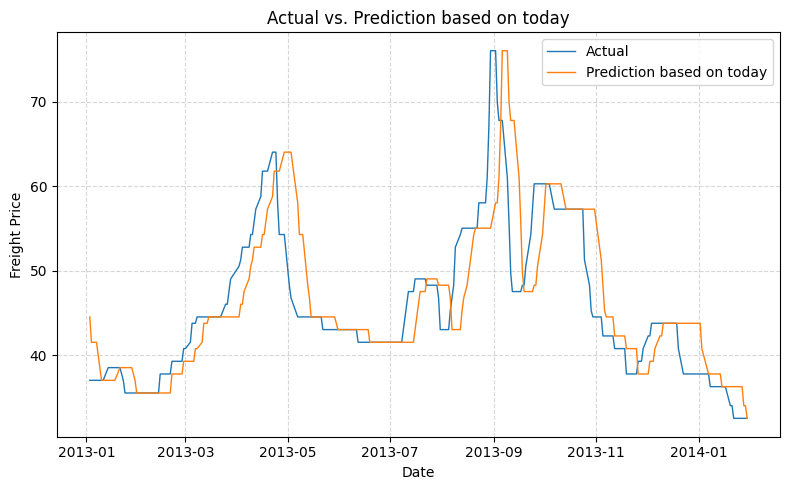

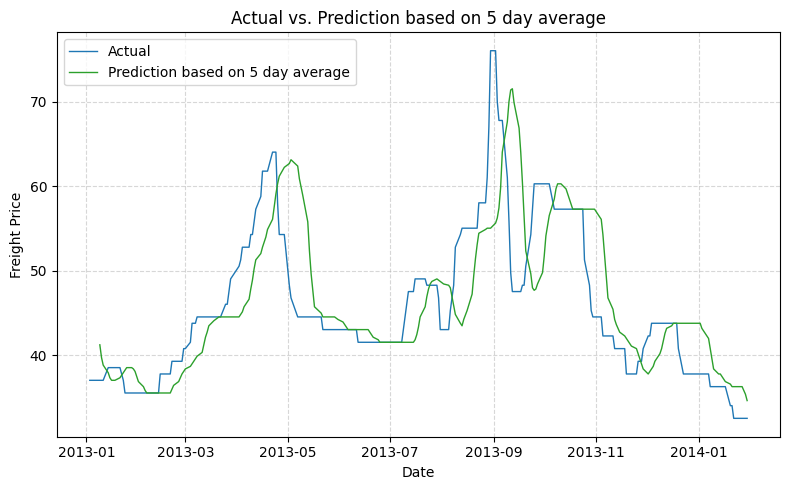

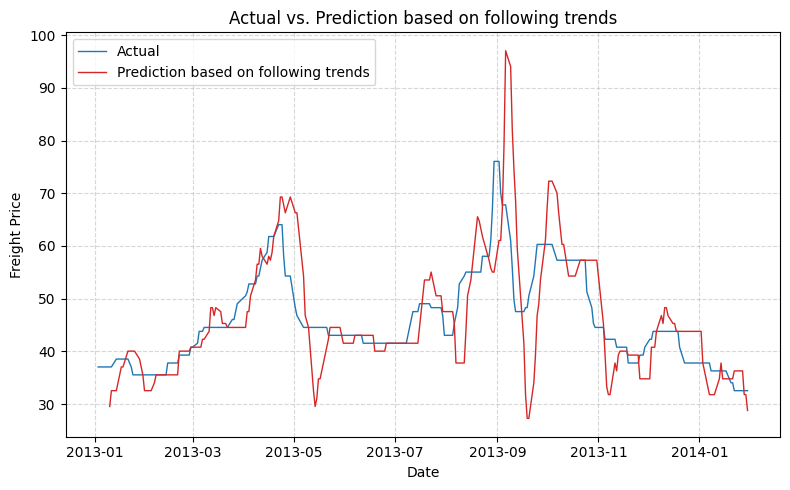

In [7]:
year = int(365 * 5 / 7)
subset = df_complete.iloc[:year]
x = subset['Date']

# Define (column_name, legend_label, line_color) for each baseline
plot_baselines = [
    ('pred_hoje', 'Prediction based on today', '#ff7f0e'),
    ('pred_media5', 'Prediction based on 5 day average', '#2ca02c'),
    ('pred_momentum', 'Prediction based on following trends', '#d62728'),
]

for pred_col, label, color in plot_baselines:
    fig, ax = plt.subplots(figsize=(8, 5))
    
    ax.plot(x, subset['Freight_5days'], label='Actual', color='#1f77b4', linewidth=1)
    ax.plot(x, subset[pred_col], label=label, color=color, linewidth=1)
    
    ax.set(title=f'Actual vs. {label}', xlabel='Date', ylabel='Freight Price')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')
    
    plt.tight_layout()

plt.show()

Cada hipotese de baseline tem vantagens e desvantagens. Pelos resultados a melhor baseline é assumir o preço de hoje para a previsao.
A media dos ultimos 5 dias tende  atrasar o sinal da trend na previsao piorando os resultados. 
A tentativa de seguir a tendencia (Hoje + variação) resulta em menores erros no inicio de tendencias mas erros amplificados quando o crescimento/diminuição de preço muda de sentido.

Por enquanto a baseline escolhida é o preço do proprio dia

# 2. Features

- Que features são mais importantes para o modelo?
- Que features são redundantes?
- Que tipo de split fazer? Cross-validation? Ter a certeza que nao existe data leakage
- Que modelos usar?
- Experimentar PCA para reduzir Weather features e gas price features?

Eliminar features claramente redundantes

## Encoding features

Encoding Date into cos e sin

In [8]:
doy = df_complete['Date'].dt.dayofyear
df_complete['Date_sin'] = np.sin(2 * np.pi * doy / 365.25)
df_complete['Date_cos'] = np.cos(2 * np.pi * doy / 365.25)

Encoding Weather Description

In [9]:
df_complete["weather_descriptions"] = df_complete["weather_descriptions"].str.strip("[]'")

In [10]:
df_complete = pd.get_dummies(df_complete, columns=['weather_descriptions'], prefix='weather', dtype=int)

In [11]:
df_complete = pd.get_dummies(df_complete, columns=['moon_phase'], prefix='moon', dtype=int)

In [12]:
df_complete.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 54 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Date                                    1449 non-null   datetime64[ns]
 1   Freight                                 1449 non-null   float64       
 2   Mogas_Flat                              1449 non-null   float64       
 3   Brent_flat                              1449 non-null   float64       
 4   Diesel_Flat                             1449 non-null   float64       
 5   Heating_Flat                            1449 non-null   float64       
 6   Kaub_level                              1449 non-null   float64       
 7   freight_ar                              714 non-null    float64       
 8   avgtemp                                 1449 non-null   float64       
 9   cloudcover                              1449 non-nul

## Correlations

In [13]:
try:
    import phik
except ImportError:
    print("phik is not installed (pip install phik) -> skipping the correlation table")
else:
    correlation_complete_data = df_complete.copy()
    correlation_complete_data["Date"] = pd.to_datetime(correlation_complete_data["Date"], errors="coerce")
    correlation_complete_data["Date"] = correlation_complete_data["Date"].map(
        lambda d: d.toordinal() if pd.notna(d) else np.nan)

    # njobs=1 to prevent a Windows crash
    correlation_matrix = correlation_complete_data.phik_matrix(njobs=1)
    corr_target = (
        correlation_matrix["Freight_5days"]
        .drop("Freight_5days")
        .sort_values(key=abs, ascending=False)
        .to_frame("corr_with_Freight_5days")
    )
    display(corr_target.round(3))

interval columns not set, guessing: ['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat', 'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover', 'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp', 'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow', 'visibility', 'wind_degree', 'wind_speed', 'windchill', 'windgust', 'Freight_5days', 'pred_hoje', 'pred_media5', 'pred_momentum', 'Date_sin', 'Date_cos', 'weather_Clear', 'weather_Cloudy', 'weather_Fog', 'weather_Freezing fog', 'weather_Light rain', 'weather_Light rain shower', 'weather_Mist', 'weather_Moderate or heavy rain shower', 'weather_Moderate rain', 'weather_Overcast', 'weather_Partly cloudy', 'weather_Patchy light rain with thunder', 'weather_Patchy rain possible', 'weather_Thundery outbreaks possible', 'moon_First Quarter', 'moon_Full Moon', 'moon_Last Quarter', 'moon_New Moon', 'moon_Waning Crescent', 'moon_Waning Gibbous', 'moon_Waxing Crescent', 'moon_Waxing Gibbous']


,corr_with_Freight_5days
Freight,0.958
pred_hoje,0.958
pred_media5,0.942
pred_momentum,0.940
freight_ar,0.890
Kaub_level,0.738
Date,0.721
Brent_flat,0.604
Date_sin,0.575
Date_cos,0.544


# 3. Two training splits

Both are walk-forward (`TimeSeriesSplit`, 5 folds, `gap=5` so the 5-day-ahead targets of the last training rows never overlap the test period):

- **expanding (default)**: train on all the past data;
- **rolling (500)**: train only on the last 500 rows.

The test folds are identical in both, only the amount of history used for training changes. Every model below is evaluated on both.

In [14]:
df_model = df_complete.copy()
df_model['freight_ar'] = df_model['freight_ar'].fillna(0)

target = "Freight_5days"
baseline_cols = ["pred_hoje", "pred_media5", "pred_momentum"]    # kept for comparison, never used as features
X_all = df_model.drop(columns=["Date", target] + baseline_cols)   # every feature
y = df_model[target]
dates = df_model["Date"]
today = df_model["Freight"]                                       # price at time t

splitters = {
    "expanding (default)": TimeSeriesSplit(n_splits=5, gap=5),                       # train on all past data
    "rolling (500)":       TimeSeriesSplit(n_splits=5, gap=5, max_train_size=500),   # train on the last 500 rows only
}

# Overview of the folds
rows = []
for scheme, s in splitters.items():
    for fold, (tr, te) in enumerate(s.split(X_all)):
        rows.append({"split": scheme, "fold": fold,
                     "train start": dates.iloc[tr[0]].date(), "train end": dates.iloc[tr[-1]].date(), "n train": len(tr),
                     "test start": dates.iloc[te[0]].date(), "test end": dates.iloc[te[-1]].date(), "n test": len(te)})
folds_table = pd.DataFrame(rows).set_index(["split", "fold"])

# "Extreme days" = top 10% of the actual 5-day-ahead price among all test rows
test_rows = np.unique(np.concatenate([te for _, te in splitters["expanding (default)"].split(X_all)]))
EXT_THR = y.iloc[test_rows].quantile(0.90)
print(f"Extreme days: actual >= {EXT_THR:.1f}")
folds_table

Extreme days: actual >= 140.0


train start   train end  n train  test start  \
split               fold                                                
expanding (default) 0     2013-01-03  2013-12-23      239  2014-01-08   
                    1     2013-01-03  2014-12-22      480  2015-01-07   
                    2     2013-01-03  2015-12-18      721  2016-01-04   
                    3     2013-01-03  2016-12-16      962  2016-12-28   
                    4     2013-01-03  2017-12-15     1203  2017-12-27   
rolling (500)       0     2013-01-03  2013-12-23      239  2014-01-08   
                    1     2013-01-03  2014-12-22      480  2015-01-07   
                    2     2013-11-28  2015-12-18      500  2016-01-04   
                    3     2014-11-27  2016-12-16      500  2016-12-28   
                    4     2015-11-25  2017-12-15      500  2017-12-27   

                            test end  n test  
split               fold                      
expanding (default) 0     2015-01-05     241  
                    1     2015-12-30     241  
                    2     2016-12-23     241  
                    3     2017-12-22     241  
                    4     2018-12-18     241  
rolling (500)       0     2015-01-05     241  
                    1     2015-12-30     241  
                    2     2016-12-23     241  
                    3     2017-12-22     241  
                    4     2018-12-18     241

## Evaluation helpers

Everything below is built on a few small helpers, so each model is a single call:

- `run_cv`: walk-forward evaluation of one model on both splits. `delta=True` makes the model learn the 5-day **change** (`Freight_5days - Freight`) and adds today's price back; `delta=False` learns the level directly.
- Hyperparameters are always tuned **inside each fold, on the training rows only** (inner `TimeSeriesSplit` with `gap=5`): `LassoCV`, `RidgeCV`, `RandomizedSearchCV`.
- `Store`: collects per-fold results/predictions and builds the summary tables (`.show(...)` highlights the new rows).

In [15]:
# ---------- scoring: métricas + MAE on extreme days ----------
def score(y_true, y_pred, thr=None):
    out = metricas_pct(y_true, y_pred)
    if thr is not None:
        yt, yp = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
        ext = yt >= thr
        out["MAE extremos"] = metricas(yt[ext], yp[ext])["MAE"] if ext.any() else np.nan
    return out

# ---------- model factories (fresh model each fold, tuned on training rows only) ----------
ALPHAS = np.logspace(-3, 2, 40)
XGB_N_ITER = 25
XGB_PARAMS = {"n_estimators": [100, 200, 300, 400],
              "max_depth": randint(2, 7),
              "learning_rate": loguniform(0.01, 0.1)}

def inner_cv():
    return TimeSeriesSplit(n_splits=3, gap=5)

def make_lasso():
    return make_pipeline(StandardScaler(), LassoCV(alphas=ALPHAS, cv=inner_cv(), max_iter=50000))

def make_ridge():
    return make_pipeline(StandardScaler(),
                         RidgeCV(alphas=ALPHAS, cv=inner_cv(), scoring="neg_root_mean_squared_error"))

def make_xgb():
    return RandomizedSearchCV(
        XGBRegressor(objective="reg:squarederror", tree_method="hist", random_state=42, n_jobs=1),
        param_distributions=XGB_PARAMS, n_iter=XGB_N_ITER, cv=inner_cv(),
        scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1, refit=True)

def make_extratrees():
    return ExtraTreesRegressor(n_estimators=300, min_samples_leaf=10, max_features=0.5,
                               random_state=0, n_jobs=-1)

# extra info stored per fold (chosen alpha, sparsity, hyperparameters)
def info_linear(m):
    est = m[-1]
    out = {"alpha": est.alpha_}
    if isinstance(est, LassoCV):
        out["n_features"] = int((est.coef_ != 0).sum())
    return out

def info_xgb(m):
    return dict(m.best_params_)

def name(algo, tgt, feats):
    """Consistent model labels, e.g. 'Lasso (delta, Freight features)'."""
    return f"{algo} ({tgt}, {feats} features)"

# ---------- walk-forward evaluation ----------
def run_cv(label, X, y_, base, dates_, make_model, delta=False, info=None, thr=None):
    rows, preds = [], []
    for scheme, tscv_ in splitters.items():
        for fold, (tr, te) in enumerate(tscv_.split(X)):
            off_tr = base.iloc[tr] if delta else 0          # delta: learn y(t+5) - y(t)
            off_te = base.iloc[te].values if delta else 0
            model = make_model()
            model.fit(X.iloc[tr], y_.iloc[tr] - off_tr)
            y_pred = np.asarray(model.predict(X.iloc[te])) + off_te
            y_true = y_.iloc[te]

            row = {"scheme": scheme, "fold": fold, "model": label, **score(y_true, y_pred, thr)}
            if info is not None:
                row.update(info(model))
            rows.append(row)
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": label,
                                       "Date": dates_.iloc[te].values, "actual": y_true.values,
                                       "pred": y_pred, "benchmark": base.iloc[te].values}))
    return pd.DataFrame(rows), pd.concat(preds, ignore_index=True)

def run_benchmark(label, y_, pred, thr=None):
    rows = []
    for scheme, tscv_ in splitters.items():
        for fold, (tr, te) in enumerate(tscv_.split(np.arange(len(y_)))):
            rows.append({"scheme": scheme, "fold": fold, "model": label,
                         **score(y_.iloc[te], pred.iloc[te], thr)})
    return pd.DataFrame(rows)

# ---------- results container + tables ----------
METRIC_ORDER = ["MAE", "RMSE", "Erro máx", "MAPE (%)", "MAE extremos"]
HIGHLIGHT = "background-color: #ffe066; color: #000; font-weight: bold"

class Store:
    """Per-fold results and predictions of every model + summary tables."""
    def __init__(self, y, base, dates, ext_thr=None, forbidden=()):
        self.y, self.base, self.dates = y, base, dates
        self.thr, self.forbidden = ext_thr, list(forbidden)
        self.res, self.preds = pd.DataFrame(), pd.DataFrame()

    def add(self, res, preds=None):
        self.res = res.copy() if self.res.empty else pd.concat([self.res, res], ignore_index=True)
        if preds is not None:
            self.preds = preds.copy() if self.preds.empty else pd.concat([self.preds, preds], ignore_index=True)

    def bench(self, label, pred):
        self.add(run_benchmark(label, self.y, pred, self.thr))

    def run(self, label, X, make_model, delta=False, info=None):
        assert X.index.equals(self.y.index), "X must have exactly the same rows as y (no dropna / reordering)"
        assert not any(c in X.columns for c in self.forbidden), "target/baseline leaked into X"
        self.add(*run_cv(label, X, self.y, self.base, self.dates, make_model, delta, info, self.thr))

    def models(self):
        return list(self.res["model"].unique())

    def summary(self, models=None):
        """Mean across folds. Rows = models, columns = (split, metric)."""
        models = models or self.models()
        cols = [c for c in METRIC_ORDER if c in self.res.columns]
        g = self.res[self.res["model"].isin(models)].groupby(["scheme", "model"])[cols].mean()
        out = pd.concat({s: g.loc[s].reindex(models) for s in splitters}, axis=1)
        out.index.name = "model"
        return out

    def show(self, models=None, new=(), title=None):
        """Display the summary table; rows in `new` are highlighted. Returns the DataFrame."""
        tab, new = self.summary(models), set(new)
        hl = lambda row: [HIGHLIGHT if row.name in new else ""] * len(row)
        if title:
            print(title)
        display(tab.style.apply(hl, axis=1).format("{:.2f}", na_rep="–"))
        return tab

    def folds(self, models, metrics=("MAE", "RMSE")):
        """Per-fold detail (use sparingly)."""
        r = self.res[self.res["model"].isin(models)]
        t = r.pivot_table(index=["scheme", "fold"], columns="model", values=list(metrics))
        t = t.loc[:, [(m, mod) for m in metrics for mod in models]]
        t.columns.names = [None, None]
        display(t.round(2))
        return t

# ---------- plot: out-of-sample predictions, one panel per split ----------
def plot_model(preds, model_name, last_n=None, start=None, end=None, schemes=None):
    schemes = schemes or list(splitters)
    fig, axes = plt.subplots(len(schemes), 1, figsize=(14, 3.8 * len(schemes)))
    axes = np.atleast_1d(axes)
    for ax, scheme in zip(axes, schemes):
        full = preds[(preds["scheme"] == scheme) & (preds["model"] == model_name)].sort_values("Date")
        p = full
        if start is not None: p = p[p["Date"] >= pd.Timestamp(start)]
        if end   is not None: p = p[p["Date"] <= pd.Timestamp(end)]
        if last_n is not None: p = p.tail(last_n)

        ax.plot(p["Date"], p["actual"], color="black", lw=1.4, label="Actual (5 days ahead)")
        ax.plot(p["Date"], p["pred"], color="tab:blue", lw=1.1, alpha=0.85, label=f"{model_name}")
        ax.plot(p["Date"], p["benchmark"], color="tab:grey", lw=1, ls="--", alpha=0.8, label="Benchmark (today)")

        lo, hi = p["Date"].min(), p["Date"].max()
        for f, g in full.groupby("fold"):                       # fold starts inside the window
            d0 = g["Date"].min()
            if lo <= d0 <= hi:
                ax.axvline(d0, color="grey", lw=0.6, ls=":")
        ax.set_xlim(lo, hi)
        if (hi - lo).days > 700:
            ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        else:
            ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        ax.set_ylabel("Freight"); ax.legend(frameon=False, loc="upper left")
        ax.set_title(f"{model_name}, {scheme}", loc="left", fontweight="bold")
        ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

# 4. Predicting Freight

Target: `Freight_5days`. Features available at day *t*: Freight prices, fuels, Kaub level, weather. "Level" models predict the price in 5 days directly, "delta" models predict the 5-day change.

In [16]:
freight = Store(y=y, base=today, dates=dates, ext_thr=EXT_THR,
                forbidden=["Freight_5days"] + baseline_cols)

# Baselines, evaluated on exactly the same folds
freight.bench("Benchmark (today)",                 df_model["pred_hoje"])
freight.bench("Baseline: 5-day mean",              df_model["pred_media5"])
freight.bench("Baseline: today + 5-day change",    df_model["pred_momentum"])

## 4.1 Lasso on every feature

In [17]:
M_lasso_all = name("Lasso", "level", "all")
freight.run(M_lasso_all, X_all, make_lasso, delta=False, info=info_linear)

# per-fold detail (shown only here, the rest of the notebook uses the mean across folds)
freight.folds(["Benchmark (today)", M_lasso_all])
freight.show(new=[M_lasso_all], title="Mean across folds:");

MAE                              \
                         Benchmark (today) Lasso (level, all features)   
scheme              fold                                                 
expanding (default) 0                 2.27                        3.71   
                    1                 8.02                       14.20   
                    2                 5.43                        8.35   
                    3                 6.50                        7.91   
                    4                12.65                       16.68   
rolling (500)       0                 2.27                        3.71   
                    1                 8.02                       14.20   
                    2                 5.43                       11.34   
                    3                 6.50                       11.50   
                    4                12.65                       26.48   

                                      RMSE                              
                         Benchmark (today) Lasso (level, all features)  
scheme              fold                                                
expanding (default) 0                 3.28                        4.42  
                    1                15.83                       22.17  
                    2                 9.55                       10.61  
                    3                11.96                       11.97  
                    4                31.67                       31.86  
rolling (500)       0                 3.28                        4.42  
                    1                15.83                       22.17  
                    2                 9.55                       13.17  
                    3                11.96                       14.88  
                    4                31.67                       39.14

Mean across folds:


Lasso regression has "built-in" feature engineering so there is no difference in selecting most relevant features and less relevant features, since the Lasso regression will set redundant coefficients closer to zero.

Comparing Lasso with baselines max error for Lasso was lower while the MAE and RMSE were similar (or even slightly worse)

## 4.2 Lasso on Freight features

Only today's price, `freight_ar` and the past 1/2/5-day changes of Freight.

In [18]:
def add_features_updated(X):
    """Freight-only features: price, freight_ar and past changes (no future info)."""
    X1 = X[['Freight', 'freight_ar']].copy()
    f = X1["Freight"]
    for k in [1, 2, 5]:
        X1[f"Freight_d{k}"] = f.diff(k).fillna(0)   # no past value -> no change
    return X1

X1 = add_features_updated(df_model)                 # built from df_model, not from X_all
print("Freight features:", list(X1.columns))

M_lasso_fr = name("Lasso", "level", "Freight")
freight.run(M_lasso_fr, X1, make_lasso, delta=False, info=info_linear)
freight.show(new=[M_lasso_fr]);

Freight features: ['Freight', 'freight_ar', 'Freight_d1', 'Freight_d2', 'Freight_d5']


## 4.3 Lasso delta

### How the delta models work (modelling the change)

Instead of predicting the price level in 5 days directly, the model learns the **5-day change** (`Freight_5days - Freight`) and today's price is added back to get the level forecast. The linear models then start from the "today's price" baseline and only have to learn the correction.

- Same features (`X1`) and same splits (`splitters`) as the level models above, so the comparison is fair.
- The regularisation strength (alpha) is tuned **inside each fold, on the training data only** (`RidgeCV` / `LassoCV` with a time-series inner split and `gap=5`), so nothing from the test period is used to choose it.

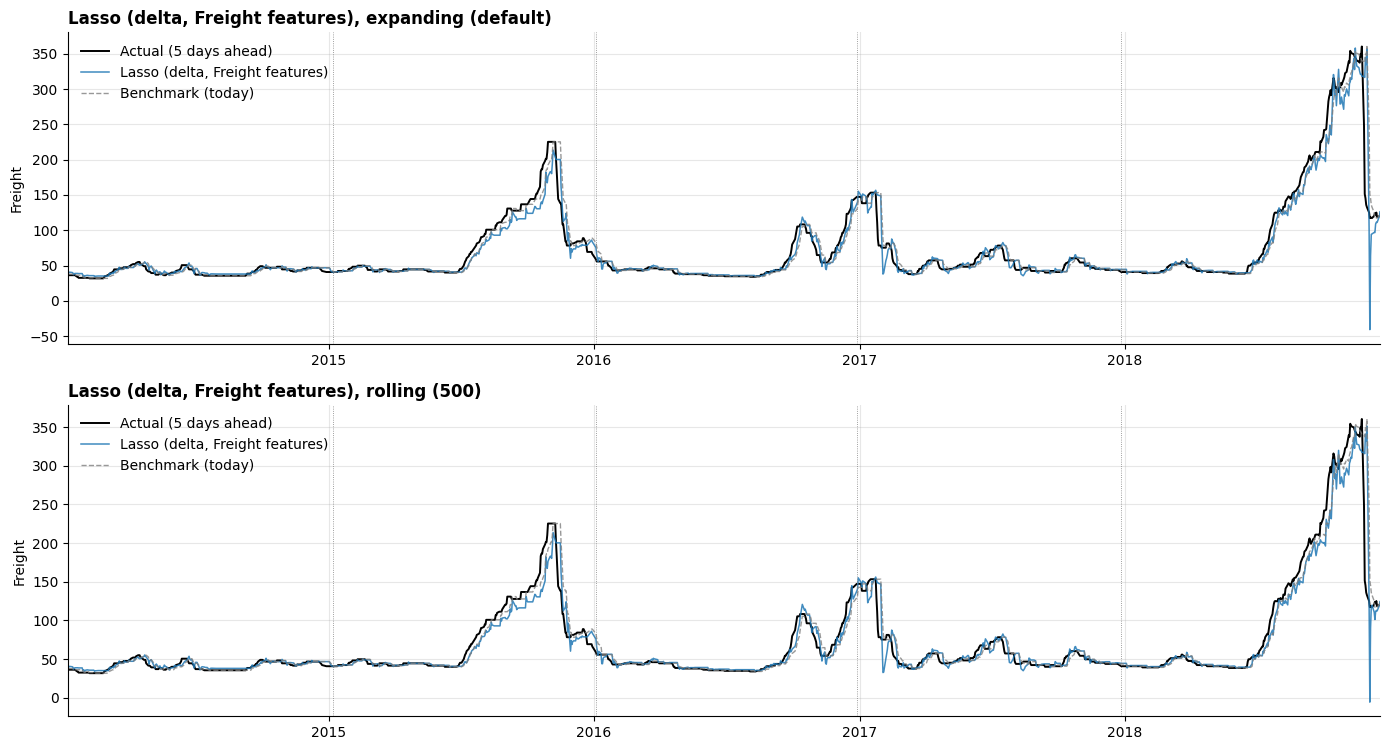

In [19]:
M_lasso_d = name("Lasso", "delta", "Freight")
freight.run(M_lasso_d, X1, make_lasso, delta=True, info=info_linear)
freight.show(new=[M_lasso_d])
plot_model(freight.preds, M_lasso_d)

## 4.4 Ridge

In [20]:
M_ridge = name("Ridge", "level", "Freight")
freight.run(M_ridge, X1, make_ridge, delta=False, info=info_linear)
freight.show(new=[M_ridge]);

## 4.5 Ridge delta

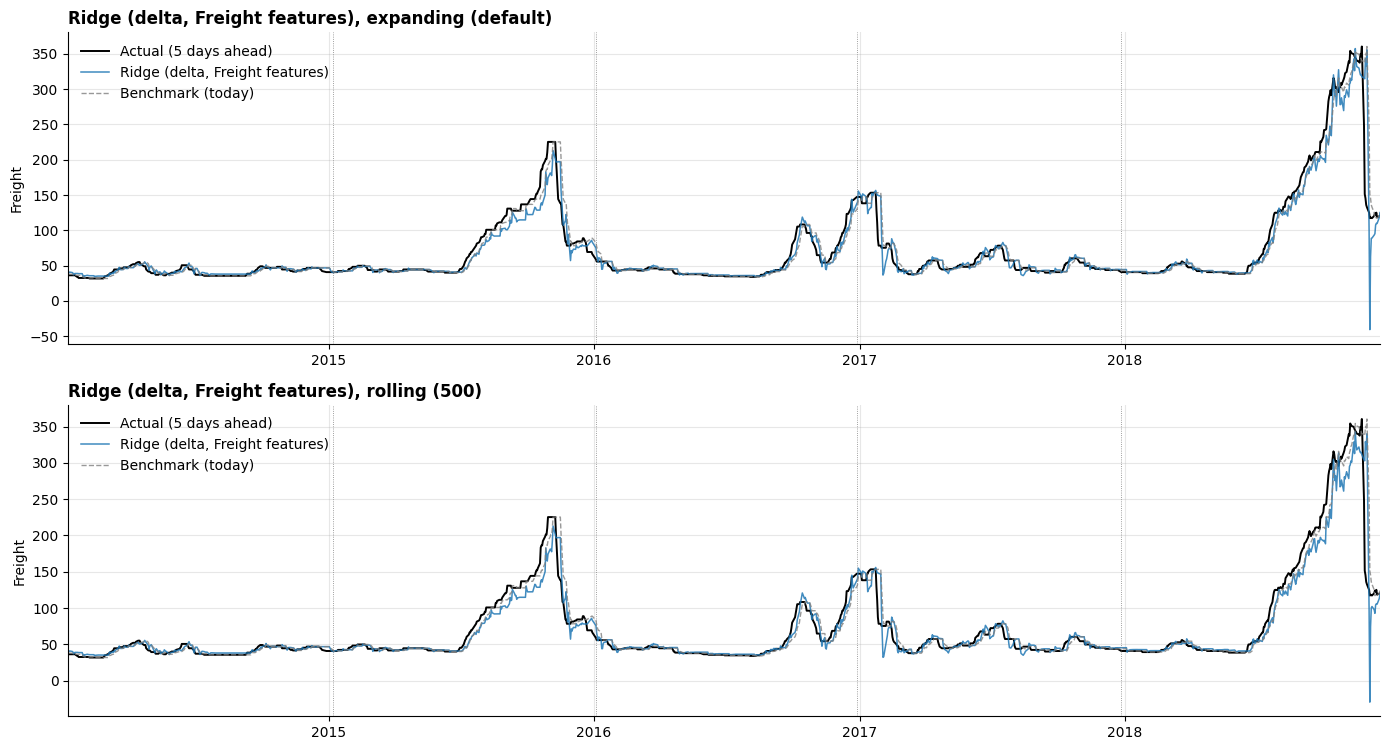

In [21]:
M_ridge_d = name("Ridge", "delta", "Freight")
freight.run(M_ridge_d, X1, make_ridge, delta=True, info=info_linear)
freight.show(new=[M_ridge_d])
plot_model(freight.preds, M_ridge_d)

## 4.6 XGBoost

On **every** feature, predicting the price level (hyperparameters from `RandomizedSearchCV`, inner time-series CV).

In [22]:
M_xgb_all = name("XGBoost", "level", "all")
freight.run(M_xgb_all, X_all, make_xgb, delta=False, info=info_xgb)
freight.show(new=[M_xgb_all]);

## 4.7 XGBoost delta

MAE  \
                         Lasso (delta, Freight features)   
scheme              fold                                   
expanding (default) 0                               2.65   
                    1                               9.69   
                    2                               4.27   
                    3                               6.55   
                    4                              13.81   
rolling (500)       0                               2.65   
                    1                               9.69   
                    2                               4.32   
                    3                               6.81   
                    4                              14.18   

                                                        \
                         XGBoost (delta, all features)   
scheme              fold                                 
expanding (default) 0                             2.30   
                    1                            10.56   
                    2                             5.47   
                    3                             6.45   
                    4                            15.67   
rolling (500)       0                             2.30   
                    1                            10.56   
                    2                             5.62   
                    3                             8.04   
                    4                            14.10   

                                                    RMSE  \
                         Lasso (delta, Freight features)   
scheme              fold                                   
expanding (default) 0                               3.27   
                    1                              15.40   
                    2                               6.97   
                    3                              11.59   
                    4                              32.05   
rolling (500)       0                               3.27   
                    1                              15.40   
                    2                               6.81   
                    3                              11.84   
                    4                              31.42   

                                                        
                         XGBoost (delta, all features)  
scheme              fold                                
expanding (default) 0                             3.27  
                    1                            16.82  
                    2                             9.42  
                    3                            10.73  
                    4                            31.99  
rolling (500)       0                             3.27  
                    1                            16.82  
                    2                             9.43  
                    3                            11.23  
                    4                            31.01

Mean across folds:


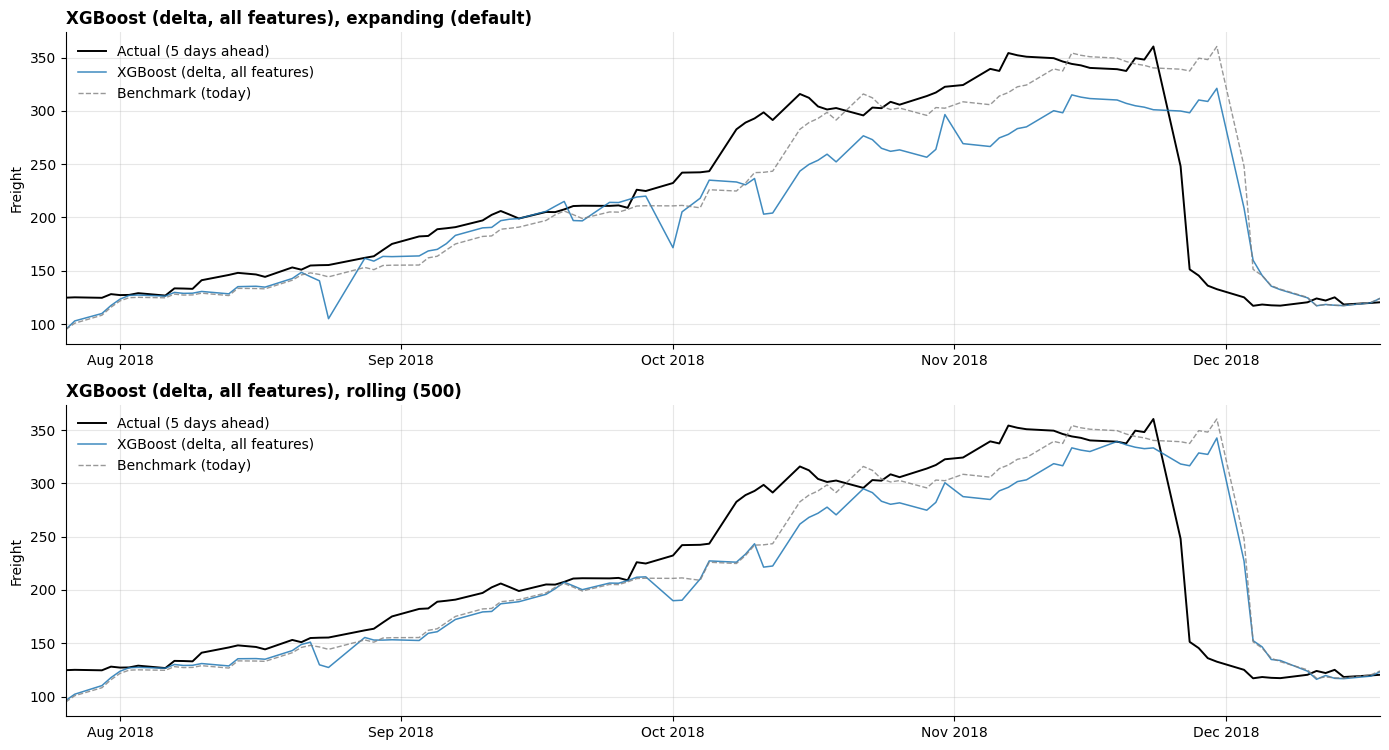

In [23]:
M_xgb_all_d = name("XGBoost", "delta", "all")
freight.run(M_xgb_all_d, X_all, make_xgb, delta=True, info=info_xgb)

freight.folds([M_lasso_d, M_xgb_all_d])        # per-fold detail (2nd time)
freight.show(new=[M_xgb_all_d], title="Mean across folds:")
plot_model(freight.preds, M_xgb_all_d, last_n=100)

### SHAP

Which features does XGBoost (delta, every feature) actually use? This motivates the *Freight features* subset in 4.8.

c:\Users\PedroJorge\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


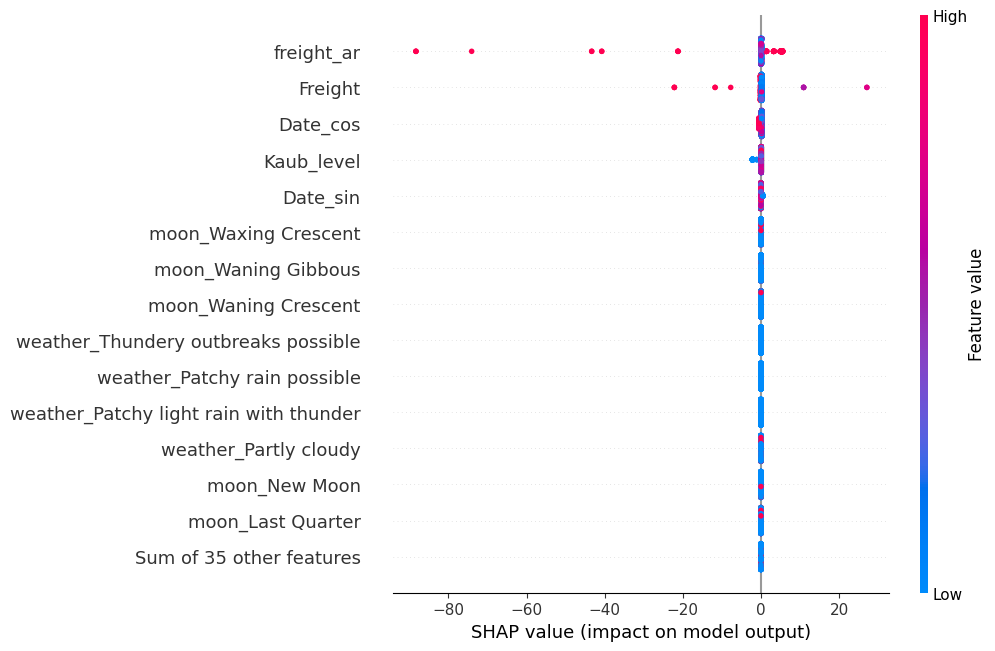

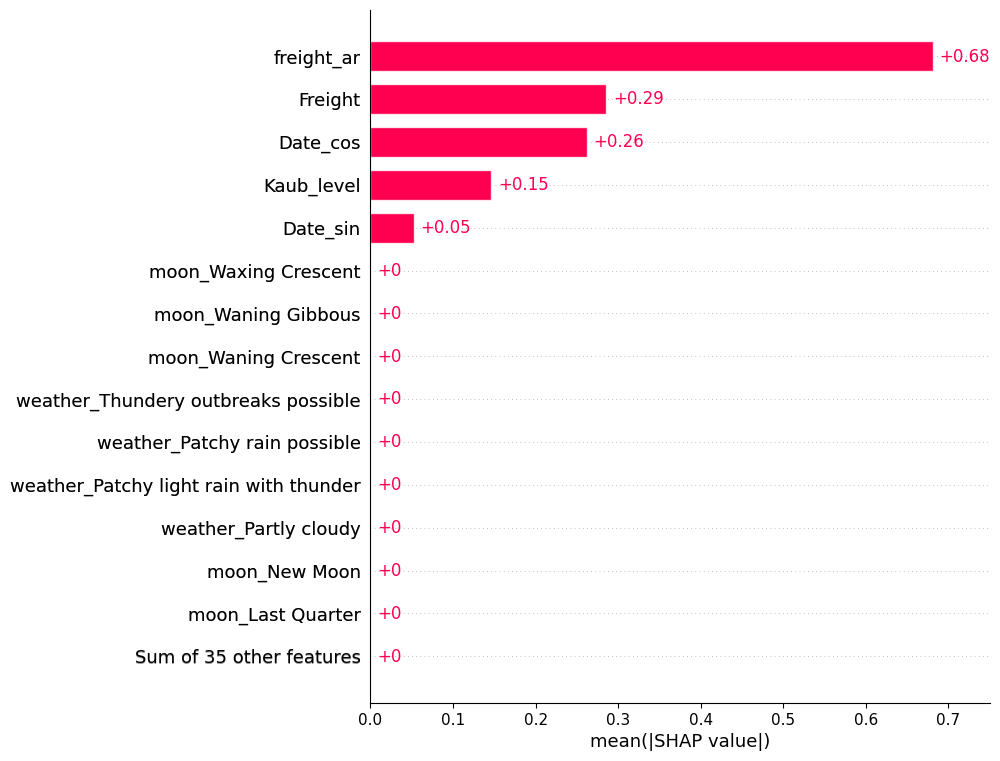

In [24]:
try:
    import shap
except ImportError:
    print("shap is not installed (pip install shap) -> skipping")
else:
    # hyperparameters chosen in the last expanding fold (the one trained on the most data)
    r = freight.res
    bp = (r[(r["model"] == M_xgb_all_d) & (r["scheme"] == "expanding (default)")]
          .sort_values("fold").iloc[-1][["n_estimators", "max_depth", "learning_rate"]].to_dict())
    bp["n_estimators"], bp["max_depth"] = int(bp["n_estimators"]), int(bp["max_depth"])

    # refit on the same target the model learned (the 5-day change)
    shap_model = XGBRegressor(**bp, tree_method="hist", random_state=42, n_jobs=1).fit(X_all, y - today)
    sv = shap.TreeExplainer(shap_model)(X_all)
    shap.plots.beeswarm(sv, max_display=15)     # direction and size of each feature's effect
    shap.plots.bar(sv, max_display=15)          # mean |SHAP|, a simple importance ranking

## 4.8 Previous models on Freight features

Updated features based on shap

Lasso and Ridge already run on the Freight features (4.2 to 4.5). XGBoost is the model that was still using every feature, so here it is re-run on the Freight features (level and delta).

Predicting Freight, all models so far (mean across folds):


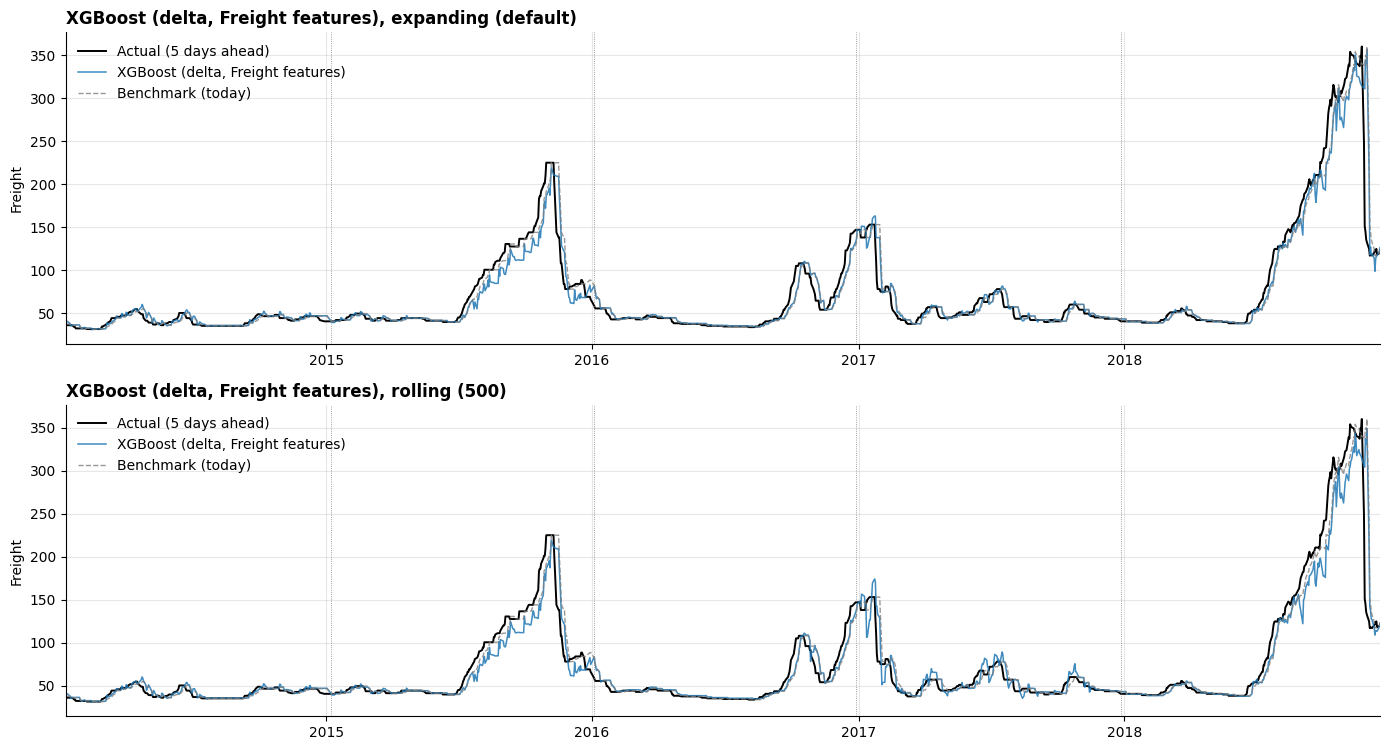

In [25]:
M_xgb_fr   = name("XGBoost", "level", "Freight")
M_xgb_fr_d = name("XGBoost", "delta", "Freight")
freight.run(M_xgb_fr,   X1, make_xgb, delta=False, info=info_xgb)
freight.run(M_xgb_fr_d, X1, make_xgb, delta=True,  info=info_xgb)

tab_freight = freight.show(new=[M_xgb_fr, M_xgb_fr_d], title="Predicting Freight, all models so far (mean across folds):")
plot_model(freight.preds, M_xgb_fr_d)

# 5. Predicting Kaub level

The Kaub water level drives the freight price (low water = fewer/lighter barges). Can we forecast the level 5 days ahead from the weather? Target: Kaub level at *t+5*; the model learns the 5-day change and today's level is added back. Benchmark: persistence (today's level).

In [26]:
# ---------- feature builders ----------
def add_memory_features(df_model, df_weather):
    cols = ["Date", "avgtemp", "pressure", "humidity", "cloudcover", "totalsnow", "wind_degree"]
    w = (df_weather[cols].drop_duplicates("Date").set_index("Date").sort_index().asfreq("D"))

    f = pd.DataFrame(index=w.index)
    for n in (3, 7, 14, 30):
        f[f"temp_mean_{n}"] = w["avgtemp"].rolling(n, min_periods=1).mean()
    f["temp_trend"] = f["temp_mean_3"] - f["temp_mean_14"]

    f["pressure_mean_7"] = w["pressure"].rolling(7, min_periods=1).mean()
    for k in (1, 3, 5):
        f[f"pressure_d{k}"] = w["pressure"].diff(k)

    for n in (3, 7, 14):
        f[f"humidity_mean_{n}"] = w["humidity"].rolling(n, min_periods=1).mean()
        f[f"cloudcover_mean_{n}"] = w["cloudcover"].rolling(n, min_periods=1).mean()

    for n in (14, 30):
        f[f"snow_sum_{n}"] = w["totalsnow"].rolling(n, min_periods=1).sum()

    f["wind_sin_3"] = np.sin(np.deg2rad(w["wind_degree"])).rolling(3, min_periods=1).mean()
    f["wind_cos_3"] = np.cos(np.deg2rad(w["wind_degree"])).rolling(3, min_periods=1).mean()

    f = f.reset_index().rename(columns={"index": "Date"})
    out = df_model[["Date"]].merge(f, on="Date", how="left")
    out.index = df_model.index
    return out.drop(columns="Date").fillna(0)


def add_kaub_features(df_model):
    k = df_model["Kaub_level"]
    out = pd.DataFrame({"Kaub": k}, index=df_model.index)
    for d in (1, 3, 5, 10):
        out[f"Kaub_d{d}"] = k.diff(d).fillna(0)
    return out

## 5.1 Lasso weather

MAE                            RMSE  \
                         Benchmark (today) Lasso weather Benchmark (today)   
scheme              fold                                                     
expanding (default) 0                39.83         39.13             53.97   
                    1                42.67         42.22             64.32   
                    2                55.33         52.07             74.56   
                    3                50.35         44.87             67.28   
                    4                47.72         43.82             78.30   
rolling (500)       0                39.83         39.13             53.97   
                    1                42.67         42.22             64.32   
                    2                55.33         48.94             74.56   
                    3                50.35         50.33             67.28   
                    4                47.72         43.72             78.30   

                                        
                         Lasso weather  
scheme              fold                
expanding (default) 0            52.76  
                    1            64.22  
                    2            69.90  
                    3            58.00  
                    4            66.05  
rolling (500)       0            52.76  
                    1            64.22  
                    2            68.14  
                    3            67.41  
                    4            67.81

Kaub level, mean across folds:


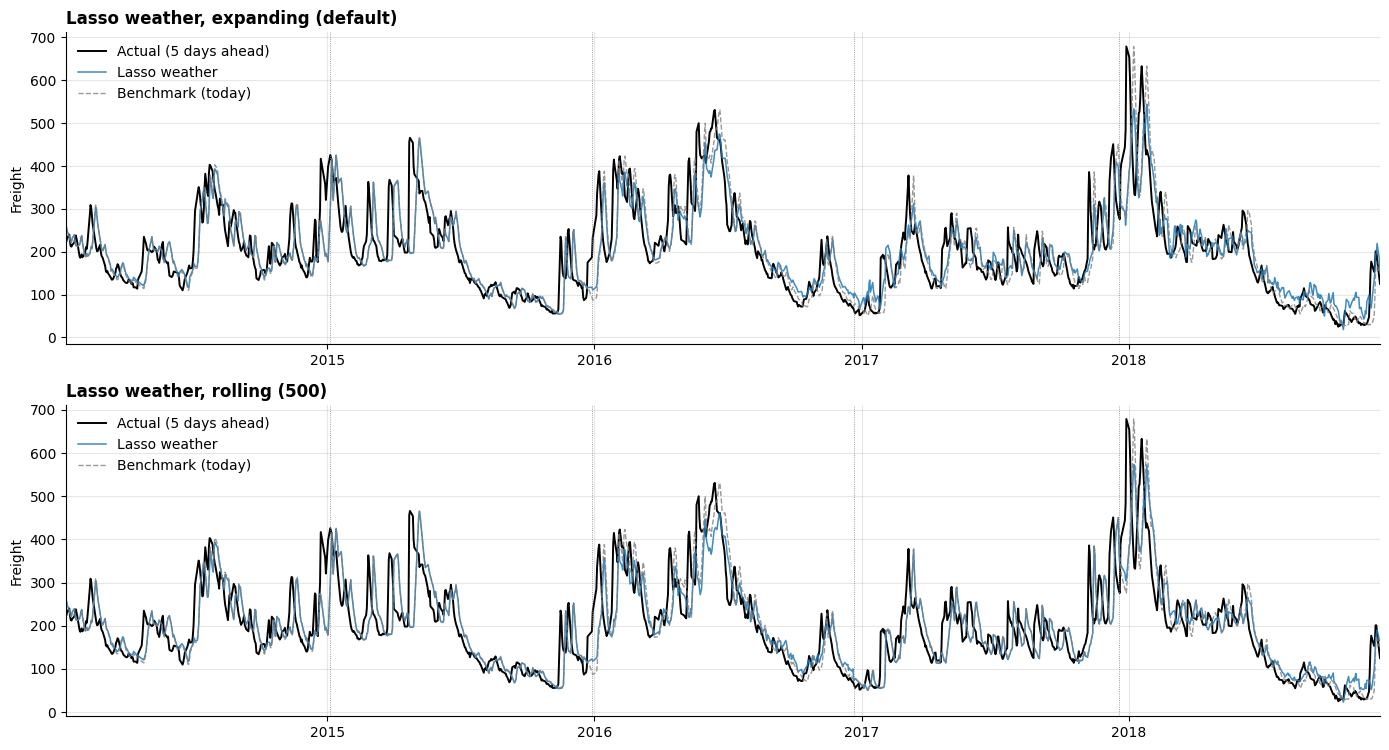

In [27]:
# ---------- features (weather only + Kaub dynamics) and target (Kaub in 5 days) ----------
weather_num = ["avgtemp", "cloudcover", "dewpoint", "feelslike", "heatindex", "humidity",
               "maxtemp", "mintemp", "precip", "pressure", "sunhour", "totalsnow",
               "visibility", "wind_degree", "wind_speed", "windchill", "windgust"]
weather_cols = weather_num + [c for c in df_model.columns if c.startswith("weather_")]

kaub_today  = df_model["Kaub_level"]
kaub_future = kaub_today.shift(-5)                 # actual level 5 days from now
mask = kaub_future.notna()                         # the last 5 rows have no target

mem    = add_memory_features(df_model, df_weather)
kaub_f = add_kaub_features(df_model)
Xk = pd.concat([df_model[weather_cols], mem, kaub_f], axis=1)[mask]

kaub = Store(y=kaub_future[mask], base=kaub_today[mask], dates=dates[mask])     # no "extreme days" column for Kaub
kaub.bench("Benchmark (today)", kaub_today[mask])

M_k_weather = "Lasso weather"
kaub.run(M_k_weather, Xk, make_lasso, delta=True, info=info_linear)

kaub.folds(["Benchmark (today)", M_k_weather])              # per-fold detail
kaub.show(new=[M_k_weather], title="Kaub level, mean across folds:")
plot_model(kaub.preds, M_k_weather)

## 5.2 Making it rain

*Spoiler alert: não funciona.*

A ideia era: quantidade de chuva e neve sao as features que tem mais informação sobre como o kaub level vai ser daqui a uns dias por isso bora estimar a probailidade de chover com base em features de humidade, visibilidade, ceu coberto, etc 

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

w = df_weather.sort_values("Date").drop_duplicates("Date").reset_index(drop=True)
desc = w["weather_descriptions"].str.strip("[]'")
wet = ((w["precip"] > 0) | desc.str.contains("rain|shower|drizzle|snow|sleet", case=False)).astype(int)

F = pd.DataFrame({
    "humidity": w["humidity"], "cloudcover": w["cloudcover"],
    "dew_depr": w["avgtemp"] - w["dewpoint"], "visibility": w["visibility"],
    "pressure": w["pressure"], "p_d1": w["pressure"].diff().fillna(0),
    "p_d3": w["pressure"].diff(3).fillna(0), "temp": w["avgtemp"]})

lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=2000))
p = cross_val_predict(lr, F, wet, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
print("AUC of the rain classifier:", round(roc_auc_score(wet, p), 3))

lr.fit(F, wet)
w["rain_prob"] = lr.predict_proba(F)[:, 1]      # same-day weather -> P(rain); no Kaub/Freight information involved

def add_rain_features(df_model, w):
    """Rain probability today + rolled over 3/7/14/30 days on the daily calendar."""
    r = w[["Date", "rain_prob"]].set_index("Date").sort_index().asfreq("D")["rain_prob"]
    f = pd.DataFrame({"rain_prob": r})
    for n in (3, 7, 14, 30):
        f[f"rain_prob_mean_{n}"] = r.rolling(n, min_periods=1).mean()
    f = f.reset_index()
    out = df_model[["Date"]].merge(f, on="Date", how="left")
    out.index = df_model.index
    return out.drop(columns="Date").fillna(0)

Xk_rain = pd.concat([Xk, add_rain_features(df_model, w)[mask]], axis=1)
M_k_rain = "Lasso weather + rain prob"
kaub.run(M_k_rain, Xk_rain, make_lasso, delta=True, info=info_linear)

tab_kaub = kaub.show(new=[M_k_rain], title="Kaub level, mean across folds:")

AUC of the rain classifier: 0.811
Kaub level, mean across folds:


Note: the rain classifier only maps same-day weather to a rain probability (no Kaub or Freight information is used), but it is fitted once on the full weather history, so it is a slightly generous setup. If the rain features do not improve on `Lasso weather` in the table above, the extra signal is not worth it.

# 6. Predicting Freight with the help of Kaub

The Freight models of section 4 are re-run with the Kaub information added to the Freight features: today's level `Kaub` and its past 1/3/5/10-day changes (`add_kaub_features`). These are *observed* Kaub values at day *t*. The Kaub forecast of section 5 is not fed into the Freight models.

## 6.1 Previous models with Kaub features

Freight + Kaub features: ['Freight', 'freight_ar', 'Freight_d1', 'Freight_d2', 'Freight_d5', 'Kaub', 'Kaub_d1', 'Kaub_d3', 'Kaub_d5', 'Kaub_d10']
Models with Kaub features (mean across folds):


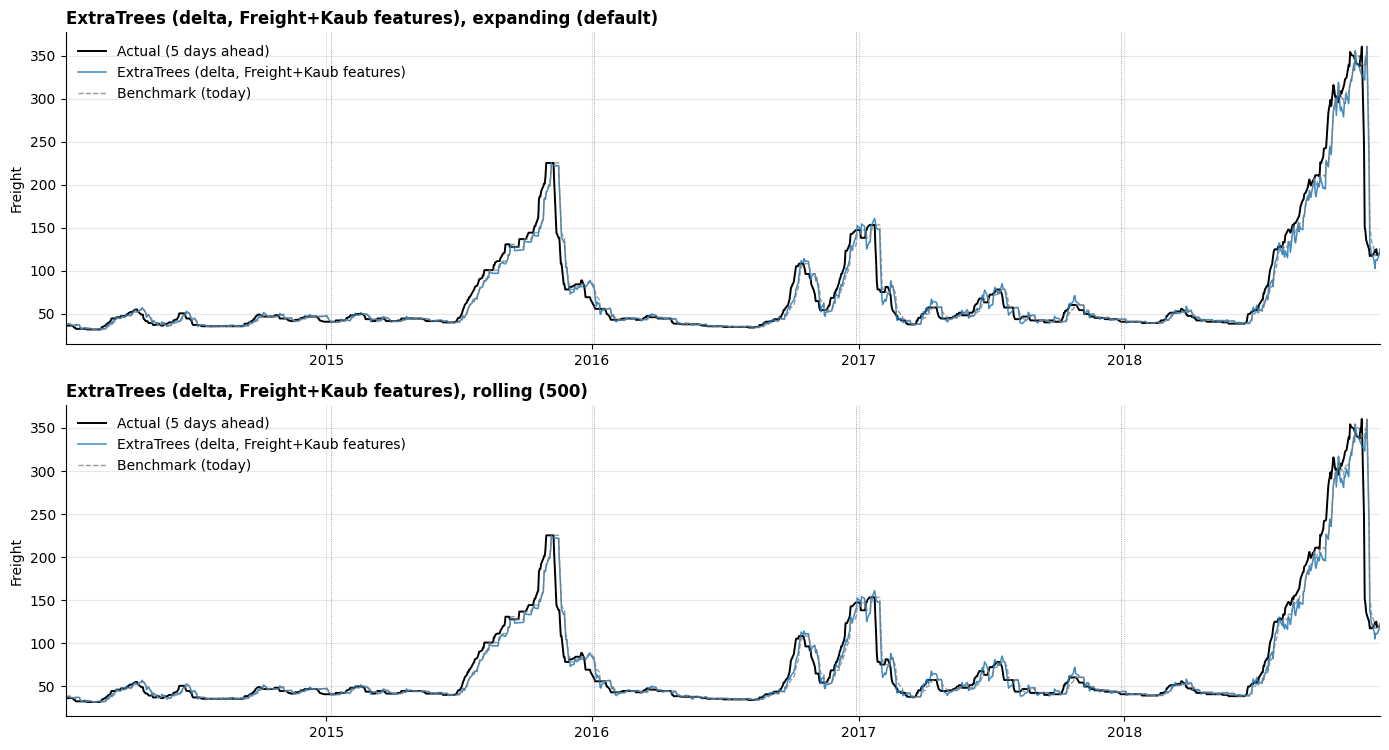

In [29]:
X_fk = pd.concat([X1, add_kaub_features(df_model)], axis=1)     # Freight features + Kaub, Kaub_d1/d3/d5/d10
print("Freight + Kaub features:", list(X_fk.columns))

kaub_variants = [("Lasso", make_lasso, info_linear), ("Ridge", make_ridge, info_linear), ("XGBoost", make_xgb, info_xgb)]
kaub_models = []
for algo, mk, inf in kaub_variants:
    for tgt in ("level", "delta"):
        label = name(algo, tgt, "Freight+Kaub")
        freight.run(label, X_fk, mk, delta=(tgt == "delta"), info=inf)
        kaub_models.append(label)

# ExtraTrees (delta) was the extra model tried with Kaub
M_et_kaub = name("ExtraTrees", "delta", "Freight+Kaub")
freight.run(M_et_kaub, X_fk, make_extratrees, delta=True)
kaub_models.append(M_et_kaub)

tab_with_kaub = freight.show(["Benchmark (today)"] + kaub_models, new=kaub_models,
                             title="Models with Kaub features (mean across folds):")
plot_model(freight.preds, M_et_kaub)

## 6.2 Comparison without Kaub features

Each model is shown right next to the same model **without** Kaub features (the Kaub version is highlighted). `ExtraTrees` had only been run with Kaub, so its Freight-only counterpart is added here for a fair comparison.

In [30]:
M_et = name("ExtraTrees", "delta", "Freight")
freight.run(M_et, X1, make_extratrees, delta=True)

pairs = [("Lasso", "level"), ("Lasso", "delta"), ("Ridge", "level"), ("Ridge", "delta"),
         ("XGBoost", "level"), ("XGBoost", "delta"), ("ExtraTrees", "delta")]
ordered, kaub_names = [], []
for algo, tgt in pairs:
    ordered += [name(algo, tgt, "Freight"), name(algo, tgt, "Freight+Kaub")]
    kaub_names.append(name(algo, tgt, "Freight+Kaub"))

tab_cmp = freight.show(["Benchmark (today)"] + ordered, new=kaub_names,
                       title="Without vs. with Kaub features (mean across folds):")

# effect of adding the Kaub features (negative = Kaub helped)
eff = {}
for algo, tgt in pairs:
    a, b = name(algo, tgt, "Freight"), name(algo, tgt, "Freight+Kaub")
    eff[f"{algo} ({tgt})"] = {(s, f"Δ{m} (%)"): (tab_cmp.loc[b, (s, m)] / tab_cmp.loc[a, (s, m)] - 1) * 100
                              for s in splitters for m in ("MAE", "RMSE")}
eff = pd.DataFrame(eff).T
eff.columns = pd.MultiIndex.from_tuples(eff.columns)
print("Change from adding Kaub features (negative = better):")
display(eff.round(1))

Without vs. with Kaub features (mean across folds):


Change from adding Kaub features (negative = better):


expanding (default)           rolling (500)          
                              ΔMAE (%) ΔRMSE (%)      ΔMAE (%) ΔRMSE (%)
Lasso (level)                      6.5       4.5           8.7       5.8
Lasso (delta)                      0.5       0.5           1.3       0.8
Ridge (level)                      3.7       1.9           6.2       3.3
Ridge (delta)                      2.3       1.3           2.4       1.4
XGBoost (level)                   -0.7       2.4           1.3       1.0
XGBoost (delta)                    1.3      -2.2          -1.3      -1.0
ExtraTrees (delta)                 0.7      -1.9           1.8      -1.7

# 7. Predicting Freight using ARX

Classic time-series benchmark: OLS on lagged daily changes of Freight (AR part) and of Kaub (exogenous part), predicting the 5-day change. The orders `(p, q)` are chosen by BIC on the training rows of each fold (`q=0` is a pure AR model).

In [31]:
# ---------- lag matrix: row t only uses information up to day t ----------
def build_arx(df, p, q):
    F, K = df["Freight"], df["Kaub_level"]
    dF, dK = F.diff(), K.diff()                         # daily changes (makes the series stationary)
    cols = {}
    for i in range(p):                                  # AR part: Freight's own past
        cols[f"dF_l{i}"] = dF.shift(i)
    for i in range(q):                                  # X part: exogenous Kaub changes
        cols[f"dK_l{i}"] = dK.shift(i)
    return pd.DataFrame(cols, index=df.index).fillna(0)  # fillna keeps rows aligned with y

def bic_ols(model, X_, y_):
    n, k = len(y_), X_.shape[1] + 1                      # +1 for the intercept
    rss = ((y_ - model.predict(X_)) ** 2).sum()
    return n * np.log(rss / n) + k * np.log(n)

y_delta = y - today                                      # target: Freight(t+5) - Freight(t)
orders  = [(p, q) for p in (1, 3, 5, 10) for q in (0, 3, 5)]
Xa_by_order = {pq: build_arx(df_model, *pq) for pq in orders}

rows_arx, preds_arx = [], []
for scheme, tscv_ in splitters.items():
    for fold, (tr, te) in enumerate(tscv_.split(df_model)):
        best = None
        for pq, Xa in Xa_by_order.items():               # choose (p, q) by BIC on the TRAINING rows only
            m = LinearRegression().fit(Xa.iloc[tr], y_delta.iloc[tr])
            bic = bic_ols(m, Xa.iloc[tr], y_delta.iloc[tr])
            if best is None or bic < best["bic"]:
                best = dict(bic=bic, p=pq[0], q=pq[1], model=m, Xa=Xa)

        y_true = y.iloc[te]
        y_pred = today.iloc[te].values + best["model"].predict(best["Xa"].iloc[te])   # add today's price back
        rows_arx.append({"scheme": scheme, "fold": fold, "model": "ARX", "p": best["p"], "q": best["q"],
                         **score(y_true, y_pred, EXT_THR)})
        preds_arx.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": "ARX",
                                       "Date": dates.iloc[te].values, "actual": y_true.values,
                                       "pred": y_pred, "benchmark": today.iloc[te].values}))

res_arx = pd.DataFrame(rows_arx)
freight.add(res_arx, pd.concat(preds_arx, ignore_index=True))

print("Orders chosen by BIC, per fold:")
display(res_arx.pivot_table(index="fold", columns="scheme", values=["p", "q"]).astype(int))

Orders chosen by BIC, per fold:


p                                 q              
scheme expanding (default) rolling (500) expanding (default) rolling (500)
fold                                                                      
0                        1             1                   0             0
1                        1             1                   0             0
2                        3            10                   0             0
3                       10             3                   0             0
4                        3             1                   0             0

All Freight models, mean across folds:


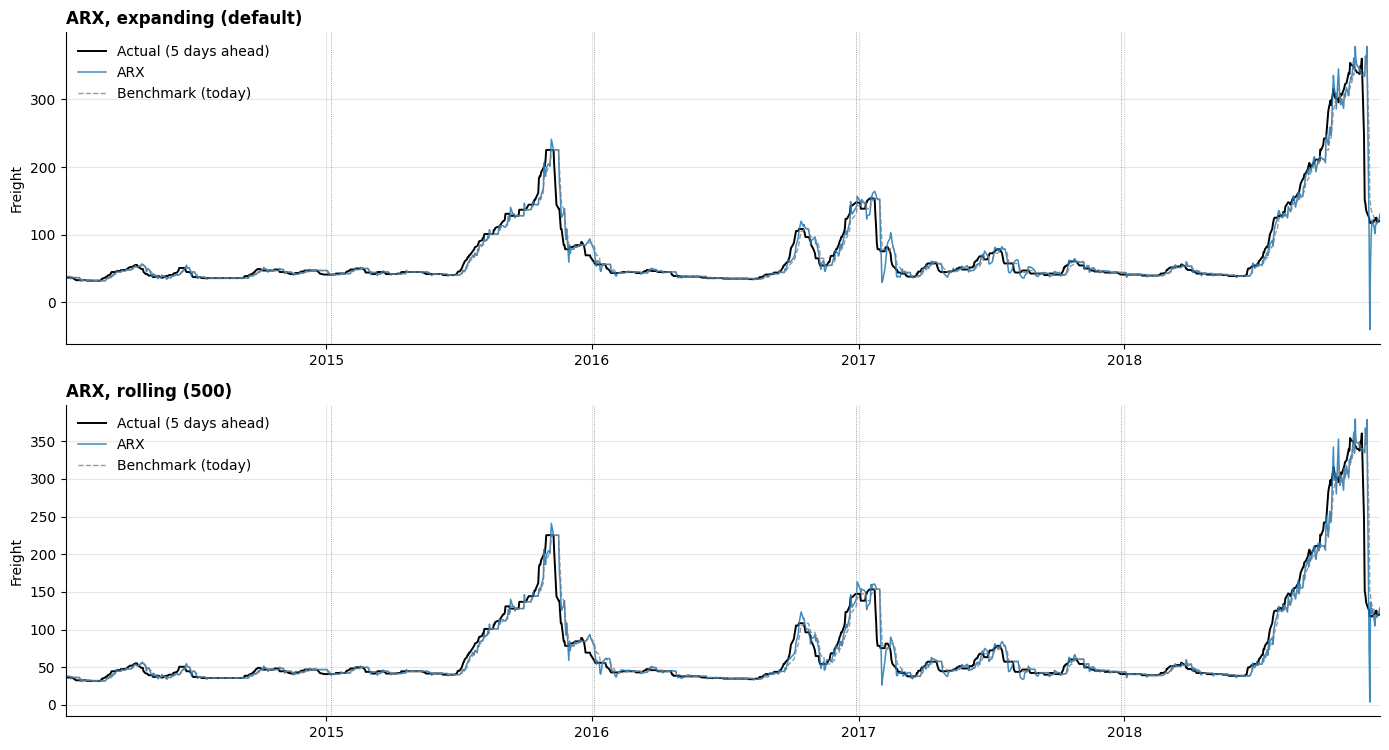

In [32]:
# ARX against everything so far (Freight target), mean across folds
tab_all = freight.show(new=["ARX"], title="All Freight models, mean across folds:")
plot_model(freight.preds, "ARX")

# 8. Quantile regression - the Risk Band

Quantile regression estimates a high percentile of the future price, here the 90th, so the risk band marks the level that the price in 5 days is expected to stay below on about 90% of days, widening when conditions such as low water make a spike more likely.

                                                   coverage  coverage low-water  coverage other  pinball  mean margin above today
scheme              model                                                                                                        
expanding (default) Benchmark (today + hist. q90)      0.84                0.52            0.89     2.27                     7.20
                    Quantile model                     0.81                0.61            0.83     1.85                     6.33
rolling (500)       Benchmark (today + hist. q90)      0.84                0.53            0.90     2.27                     7.95
                    Quantile model                     0.79                0.58            0.83     2.00                     6.06


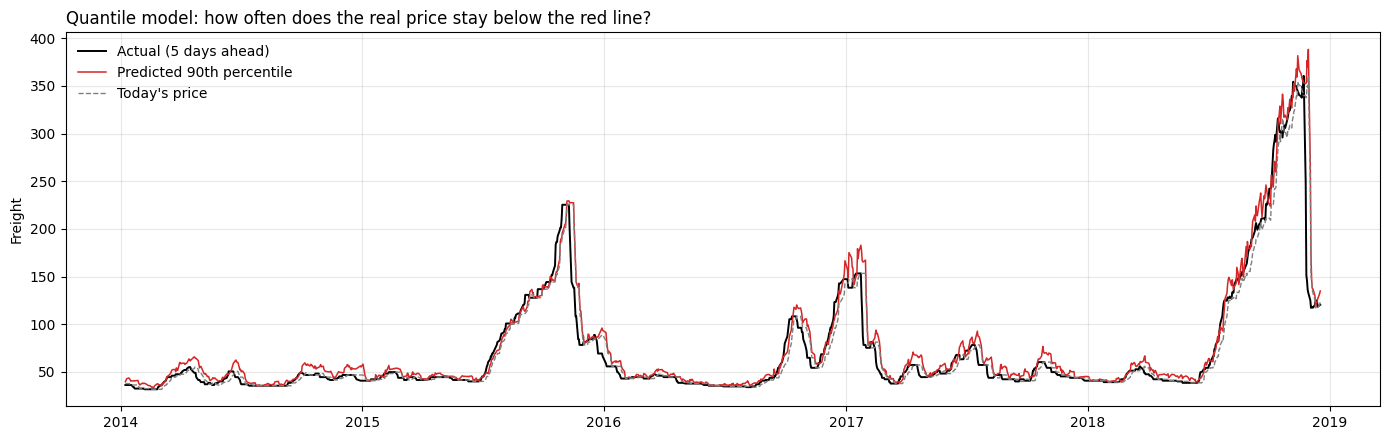

In [33]:
import numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

# ---------- features: only information up to day t ----------
def build_features(df):
    F, K = df["Freight"], df["Kaub_level"]
    X = pd.DataFrame(index=df.index)
    for i in range(3):                                   # Freight's recent daily changes
        X[f"dF_l{i}"] = F.diff().shift(i)
    X["Freight"] = F                                     # price level (regime)
    X["Kaub"] = K                                        # river level (regime)
    for d in (1, 3, 5, 10):                              # river dynamics
        X[f"Kaub_d{d}"] = K.diff(d)
    return X.fillna(0)

def pinball(y_true, y_pred, tau):
    e = y_true - y_pred
    return np.mean(np.maximum(tau * e, (tau - 1) * e))   # under-prediction costs tau, over-prediction costs 1-tau

TAU     = 0.90
Xq      = build_features(df_model)
today   = df_model["Freight"]
y_delta = y - today                                      # model the 5-day change, then add today's price back

rows, preds_q = [], []
for scheme, tscv_ in splitters.items():
    for fold, (tr, te) in enumerate(tscv_.split(Xq)):
        # quantile model
        m = HistGradientBoostingRegressor(loss="quantile", quantile=TAU, max_depth=3,
                                          learning_rate=0.05, max_iter=200,
                                          min_samples_leaf=20, random_state=0)
        m.fit(Xq.iloc[tr], y_delta.iloc[tr])
        q_model = today.iloc[te] + m.predict(Xq.iloc[te])

        # benchmark: today + the historical 90th percentile of the 5-day change (a constant)
        q_base  = today.iloc[te] + np.quantile(y_delta.iloc[tr], TAU)

        y_true = y.iloc[te]
        low_water = df_model["Kaub_level"].iloc[te] < 100          # regime at the time of the forecast
        for name, q in [("Quantile model", q_model), ("Benchmark (today + hist. q90)", q_base)]:
            rows.append({"scheme": scheme, "fold": fold, "model": name,
                         "coverage": (y_true <= q).mean(),                       # target: 0.90
                         "coverage low-water": (y_true[low_water] <= q[low_water]).mean() if low_water.any() else np.nan,
                         "coverage other": (y_true[~low_water] <= q[~low_water]).mean(),
                         "pinball": pinball(y_true, q, TAU),                     # lower is better
                         "mean margin above today": (q - today.iloc[te]).mean()})
        preds_q.append(pd.DataFrame({"scheme": scheme, "fold": fold, "Date": dates.iloc[te].values,
                                     "actual": y_true.values, "q90": q_model.values,
                                     "today": today.iloc[te].values}))

res_q   = pd.DataFrame(rows)
preds_q = pd.concat(preds_q, ignore_index=True)

print(res_q.groupby(["scheme", "model"])[["coverage", "coverage low-water", "coverage other",
                                           "pinball", "mean margin above today"]].mean().round(2).to_string())

# ---------- plot: actual price vs predicted 90th percentile (last 150 days of the expanding scheme) ----------
import matplotlib.pyplot as plt
p = preds_q[preds_q["scheme"] == "expanding (default)"].sort_values("Date")#.tail(150)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(p["Date"], p["actual"], color="black", lw=1.4, label="Actual (5 days ahead)")
ax.plot(p["Date"], p["q90"], color="tab:red", lw=1.1, label="Predicted 90th percentile")
ax.plot(p["Date"], p["today"], color="tab:grey", ls="--", lw=1, label="Today's price")
ax.set_ylabel("Freight"); ax.legend(frameon=False); ax.grid(alpha=0.3)
ax.set_title("Quantile model: how often does the real price stay below the red line?", loc="left")
plt.tight_layout(); plt.show()

## With recalibration

                                  coverage  coverage low-water  coverage other  pinball  mean margin above today
scheme              model                                                                                       
expanding (default) Plain             0.81                0.61            0.83     1.85                     6.33
                    Recalibrated      0.87                0.65            0.90     1.87                    10.30
rolling (500)       Plain             0.79                0.58            0.83     2.00                     6.06
                    Recalibrated      0.86                0.66            0.90     2.11                    10.82

Correction added to the bound, per fold:
scheme  expanding (default)  rolling (500)
fold                                      
0                      0.29           0.29
1                     -0.46          -0.46
2                      9.89          14.94
3                      3.49           9.60
4                     

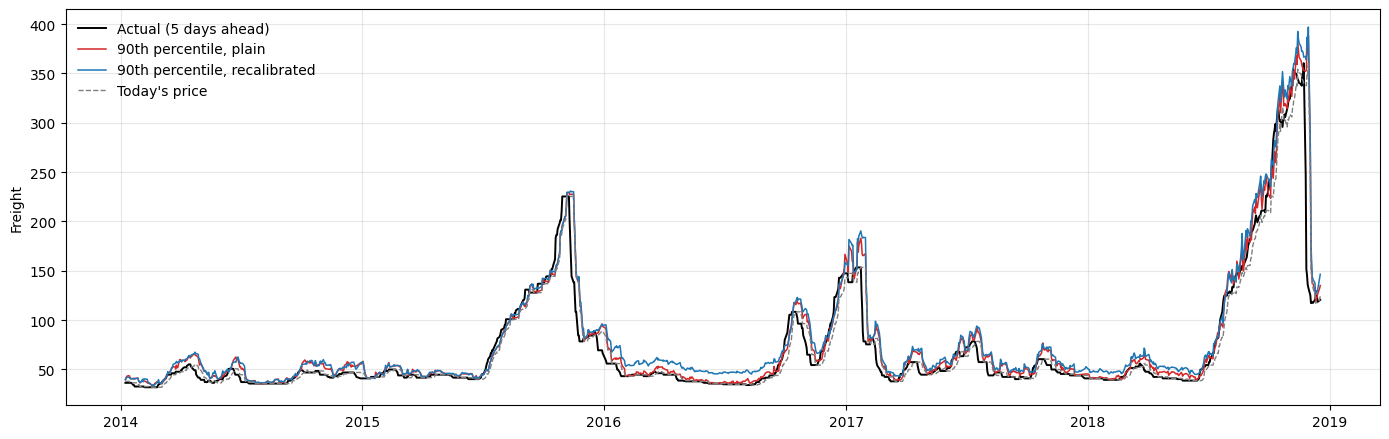

In [34]:
import numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

# ---------- same helpers as the plain quantile model ----------
def build_features(df):
    F, K = df["Freight"], df["Kaub_level"]
    X = pd.DataFrame(index=df.index)
    for i in range(3):
        X[f"dF_l{i}"] = F.diff().shift(i)
    X["Freight"] = F
    X["Kaub"] = K
    for d in (1, 3, 5, 10):
        X[f"Kaub_d{d}"] = K.diff(d)
    return X.fillna(0)

def pinball(y_true, y_pred, tau):
    e = y_true - y_pred
    return np.mean(np.maximum(tau * e, (tau - 1) * e))

def make_model(tau):
    return HistGradientBoostingRegressor(loss="quantile", quantile=tau, max_depth=3,
                                         learning_rate=0.05, max_iter=200,
                                         min_samples_leaf=20, random_state=0)

TAU     = 0.90
CAL_FRAC, GAP = 0.25, 5          # last 25% of the training rows are used for calibration, 5-row gap before them
Xq      = build_features(df_model)
today   = df_model["Freight"]
y_delta = y - today

rows, preds_c = [], []
for scheme, tscv_ in splitters.items():
    for fold, (tr, te) in enumerate(tscv_.split(Xq)):
        cut = int(len(tr) * (1 - CAL_FRAC))
        fit_idx, cal_idx = tr[:cut - GAP], tr[cut:]            # older part: fit | newer part: calibrate

        # plain model (trained on the whole training set)
        m_plain = make_model(TAU).fit(Xq.iloc[tr], y_delta.iloc[tr])
        q_plain = today.iloc[te] + m_plain.predict(Xq.iloc[te])

        # recalibrated model
        m = make_model(TAU).fit(Xq.iloc[fit_idx], y_delta.iloc[fit_idx])
        scores = (y_delta.iloc[cal_idx] - m.predict(Xq.iloc[cal_idx])).values   # how far the real change went above the predicted q90
        k = int(np.ceil((len(scores) + 1) * TAU))                              # finite-sample rank
        correction = np.sort(scores)[min(k, len(scores)) - 1]                  # shift needed to cover ~90% of calibration days
        q_conf = today.iloc[te] + m.predict(Xq.iloc[te]) + correction

        y_true = y.iloc[te]
        low_water = df_model["Kaub_level"].iloc[te] < 100
        for name, q in [("Plain", q_plain), ("Recalibrated", q_conf)]:
            rows.append({"scheme": scheme, "fold": fold, "model": name,
                         "correction": correction if name == "Recalibrated" else 0.0,
                         "coverage": (y_true <= q).mean(),                                  # target: 0.90
                         "coverage low-water": (y_true[low_water] <= q[low_water]).mean() if low_water.any() else np.nan,
                         "coverage other": (y_true[~low_water] <= q[~low_water]).mean(),
                         "pinball": pinball(y_true, q, TAU),
                         "mean margin above today": (q - today.iloc[te]).mean()})
        preds_c.append(pd.DataFrame({"scheme": scheme, "fold": fold, "Date": dates.iloc[te].values,
                                     "actual": y_true.values, "today": today.iloc[te].values,
                                     "q90_plain": q_plain.values, "q90_recal": q_conf.values}))

res_c   = pd.DataFrame(rows)
preds_c = pd.concat(preds_c, ignore_index=True)

print(res_c.groupby(["scheme", "model"])[["coverage", "coverage low-water", "coverage other",
                                          "pinball", "mean margin above today"]].mean().round(2).to_string())
print("\nCorrection added to the bound, per fold:")
print(res_c[res_c.model == "Recalibrated"].pivot(index="fold", columns="scheme", values="correction").round(2))

# ---------- plot: last 150 days of the expanding scheme ----------
import matplotlib.pyplot as plt
p = preds_c[preds_c["scheme"] == "expanding (default)"].sort_values("Date")#.tail(150)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(p["Date"], p["actual"], color="black", lw=1.4, label="Actual (5 days ahead)")
ax.plot(p["Date"], p["q90_plain"], color="tab:red", lw=1.1, label="90th percentile, plain")
ax.plot(p["Date"], p["q90_recal"], color="tab:blue", lw=1.1, label="90th percentile, recalibrated")
ax.plot(p["Date"], p["today"], color="tab:grey", ls="--", lw=1, label="Today's price")
ax.set_ylabel("Freight"); ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

recalibration helps a little but coverage on low water days is still low

# 9. Conclusions

Conclusions for the latest experiments:
- ARX has low gain compared to benchmark, probably not worth it
- quantile regression is a good indicator of probably max price flutuation for the forecast, disclosing the coverage by regime (low/high water level)
- Coverage on low water days is lower, but the cieling is higher than the actual value compared to high water level days. This shows that the model understands that there is a higher risk of price fluctuation in low water level periods.

# Appendix: LSTM

In [35]:
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler

# ---------- settings ----------
USE_KAUB   = False     # False -> only Freight features
LOOKBACK   = 10       # the LSTM sees the last 10 rows (business days)
HIDDEN     = 32
N_SEEDS    = 3        # predictions are averaged over a few seeds (LSTMs are noisy)
MAX_EPOCHS = 80
PATIENCE   = 10       # early stopping on a validation slice taken from the END of the training rows
GAP        = 5

# ---------- features: one vector per day, the LSTM builds the lags itself ----------
def build_seq_features(df, use_kaub):
    F = df["Freight"]
    X = pd.DataFrame({"dF": F.diff(), "Freight": F}, index=df.index)   # daily change + price level
    if use_kaub:
        K = df["Kaub_level"]
        X["Kaub"] = K                                                   # river level
        X["dK"] = K.diff()                                              # river daily change
    return X.fillna(0)

def make_windows(Xs, L):
    """window for row i = rows i-L+1 ... i (only past and present); the first rows are padded with row 0"""
    pad = np.repeat(Xs[:1], L - 1, axis=0)
    Xp = np.vstack([pad, Xs])
    return np.stack([Xp[i:i + L] for i in range(len(Xs))]).astype(np.float32)

# ---------- model ----------
class LSTMReg(nn.Module):
    def __init__(self, n_features, hidden):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)       # last time step -> predicted 5-day change

def fit_predict(W, y_sc, fit_idx, val_idx, te_idx, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = LSTMReg(W.shape[2], HIDDEN)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.MSELoss()
    Xf, yf = torch.tensor(W[fit_idx]), torch.tensor(y_sc[fit_idx])
    Xv, yv = torch.tensor(W[val_idx]), torch.tensor(y_sc[val_idx])

    best, best_state, wait = np.inf, None, 0
    for epoch in range(MAX_EPOCHS):
        model.train()
        perm = torch.randperm(len(Xf))
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]
            opt.zero_grad()
            loss = loss_fn(model(Xf[b]), yf[b])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(Xv), yv).item()
        if v < best - 1e-5:
            best, wait = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        return model(torch.tensor(W[te_idx])).numpy()

# ---------- same splits, same target (5-day change, then add today's price back) ----------
F_all   = build_seq_features(df_model, USE_KAUB)
today   = df_model["Freight"]
y_delta = y - today
model_name = "LSTM (Freight + Kaub)" if USE_KAUB else "LSTM (Freight only)"

results_l, preds_l = [], []
for scheme, tscv_ in splitters.items():
    for fold, (tr, te) in enumerate(tscv_.split(F_all)):
        scaler = StandardScaler().fit(F_all.iloc[tr])                   # scaler fitted on TRAIN rows only
        W  = make_windows(scaler.transform(F_all), LOOKBACK)
        sd = y_delta.iloc[tr].std()                                     # target scale from TRAIN rows only
        y_sc = (y_delta.values / sd).astype(np.float32)

        cut = int(len(tr) * 0.85)                                       # last 15% of train = validation (early stopping)
        fit_idx, val_idx = tr[:cut - GAP], tr[cut:]                     # gap: targets look 5 rows ahead

        p = np.mean([fit_predict(W, y_sc, fit_idx, val_idx, te, s) for s in range(N_SEEDS)], axis=0)
        y_pred = today.iloc[te] + p * sd
        y_true = y.iloc[te]
        bench  = today.iloc[te]

        results_l.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)", **metricas_pct(y_true, bench)})
        results_l.append({"scheme": scheme, "fold": fold, "model": model_name, **metricas_pct(y_true, y_pred)})
        preds_l.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": model_name,
                                     "Date": dates.iloc[te].values, "actual": y_true.values,
                                     "pred": y_pred.values, "benchmark": bench.values}))
        print(f"{scheme} | fold {fold} done")

res_lstm   = pd.DataFrame(results_l)
preds_lstm = pd.concat(preds_l, ignore_index=True)

# compare with ARX if it was run in this session
res_cmp = res_lstm
if "res_arx" in globals():
    res_cmp = pd.concat([res_arx[res_arx.model == "ARX"], res_lstm], ignore_index=True)

print("\nMean across folds (all days):")
print(res_cmp.groupby(["scheme", "model"])[["MAE", "RMSE", "Erro máx", "MAPE (%)"]].mean().round(2))

thr = preds_lstm["actual"].quantile(0.90)
ext = preds_lstm[preds_lstm["actual"] >= thr]
print(f"\nExtreme days (actual >= {thr:.1f}):")
print(pd.DataFrame({
    model_name:          metricas_pct(ext["actual"], ext["pred"]),
    "Benchmark (today)": metricas_pct(ext["actual"], ext["benchmark"]),
}).T.round(2))

# optional: for scheme in splitters: plot_model(preds_lstm, model_name, scheme=scheme)

expanding (default) | fold 0 done
expanding (default) | fold 1 done
expanding (default) | fold 2 done
expanding (default) | fold 3 done
expanding (default) | fold 4 done
rolling (500) | fold 0 done
rolling (500) | fold 1 done
rolling (500) | fold 2 done
rolling (500) | fold 3 done
rolling (500) | fold 4 done

Mean across folds (all days):
                                          MAE   RMSE  Erro máx  MAPE (%)
scheme              model                                               
expanding (default) ARX                  6.55  13.97     88.52      7.92
                    Benchmark (today)    6.97  14.46     86.79      8.23
                    LSTM (Freight only)  7.35  14.31     84.86      8.55
rolling (500)       ARX                  6.53  13.76     89.27      7.84
                    Benchmark (today)    6.97  14.46     86.79      8.23
                    LSTM (Freight only)  7.69  14.20     81.69      8.68

Extreme days (actual >= 141.2):
                       MAE   RMSE  Erro má